# ELL7286 / ELL784 — Assignment 1 — Linear and Logistic Regression
## Coding component

This notebook has two parts. In Part I, you will implement ordinary least squares (OLS) and gradient descent for linear regression on California Housing. In Part II, you will train and evaluate a multiclass logistic-regression classifier on the Digits dataset. Both parts use validation data for development and reserve the test set for the final evaluation.

**Running the notebook:** Use Google Colab to run the notebook: https://colab.research.google.com/. This eliminates the need to set up a local environment or install any packages manually.

**Submission:** Download the completed notebook as an `.ipynb` file from Colab. Add your entry/roll number as prefix to the filename. Submit it along with the written component.

**Rules:** Complete only the parts marked **TODO**.
Do not modify the pre-completed parts.

## Colab setup

Run the next cell once before running the rest of the notebook.

In [26]:
!pip -q install numpy matplotlib scikit-learn

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 62 #TODO: last 3 digits of your roll number

plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.grid'] = True

# Part I — Linear Regression (25 points)

## 1. Data: California Housing

The California Housing dataset contains 20,640 California census block groups. Each example has eight numerical features, and the target is median house value in units of $\$100,000$. The dataset is downloaded automatically the first time you run the next cell.

The data are split into **80% training**, **10% validation**, and **10% test** sets. Standardization is essential here because the features have different scales, and it also makes gradient descent behave reliably.

In [28]:
housing = fetch_california_housing()
X, y = housing.data, housing.target
feature_names = housing.feature_names

# First reserve the final test set, then split the remainder into training and validation.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED)

# Fit preprocessing using training data only to avoid information leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f'Training samples:   {X_train_scaled.shape[0]}')
print(f'Validation samples: {X_val_scaled.shape[0]}')
print(f'Test samples:       {X_test_scaled.shape[0]}')
print(f'Number of features: {X_train_scaled.shape[1]}')

Training samples:   16512
Validation samples: 2064
Test samples:       2064
Number of features: 8


## 2. Closed-form OLS solution (5 points)

For a design matrix $\tilde X$, augmented with a column of ones, the OLS estimator is

$$\hat{\theta} = (\tilde X^T \tilde X)^{-1} \tilde X^T y.$$

**TODO:** Complete `add_intercept` and `fit_ols_closed_form`. Use `np.linalg.solve` rather than explicitly forming a matrix inverse. Return a vector of shape `(d + 1,)`, with intercept first.

In [29]:
def add_intercept(X):
    """Return X augmented with a leading column of ones."""
    ones = np.ones((X.shape[0], 1))
    return np.hstack((ones, X))


def fit_ols_closed_form(X, y):
    """Fit OLS and return theta = [intercept, coefficient_1, ...]."""
    X_tilde = add_intercept(X)
    A = X_tilde.T @ X_tilde
    b = X_tilde.T @ y

    theta = np.linalg.solve(A, b)
    return theta


def predict(X, theta):
    """Predict targets using a parameter vector that includes an intercept."""
    return add_intercept(X) @ theta

In [30]:
# This cell is provided. Run it after completing the function above.
theta_closed = fit_ols_closed_form(X_train_scaled, y_train)
print('Closed-form parameters [intercept, standardized-feature coefficients]:')
print(np.round(theta_closed, 3))

assert theta_closed.shape == (X_train_scaled.shape[1] + 1,), 'Check the shape of theta.'
assert np.all(np.isfinite(theta_closed)), 'Theta contains non-finite values.'

Closed-form parameters [intercept, standardized-feature coefficients]:
[ 2.075  0.849  0.122 -0.287  0.307 -0.005 -0.041 -0.871 -0.843]


## 3. Gradient descent for MSE (10 points)

Let $\tilde X$ denote the augmented design matrix and let

$$R(\theta) = \frac{1}{N}\lVert \tilde X\theta - y \rVert_2^2.$$

The gradient is

$$\nabla_\theta R(\theta) = \frac{2}{N} \tilde X^T(\tilde X\theta-y).$$

**TODO:** Implement batch gradient descent below. Start from all-zero parameters, update parameters for `n_steps`, and record the loss *before* each update. Return both the final parameters and a one-dimensional loss history.

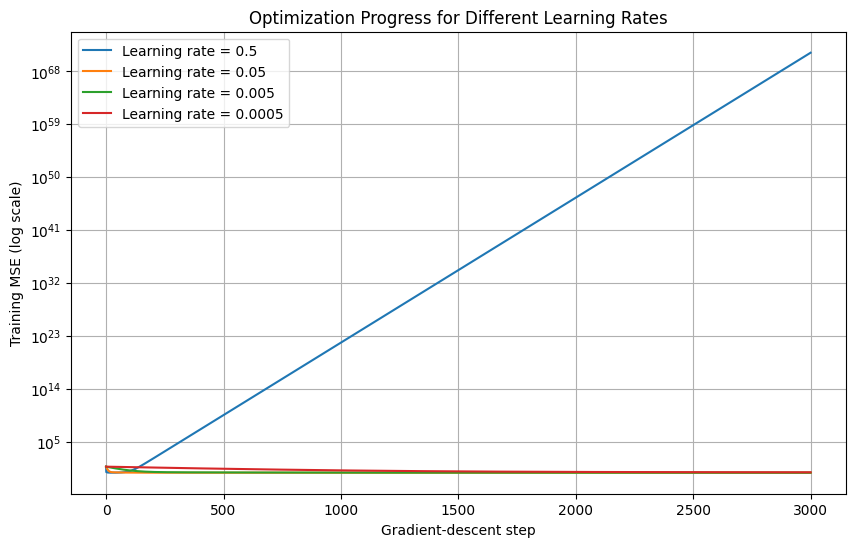

In [31]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def fit_gradient_descent(X, y, learning_rate=0.005, n_steps=3000):
    """Fit linear regression with batch gradient descent."""
    X_tilde = add_intercept(X)
    N = X_tilde.shape[0]

    theta = np.zeros(X_tilde.shape[1])
    loss_history = []

    for _ in range(n_steps):
        y_pred = X_tilde @ theta

        # Record loss BEFORE parameter update
        loss = mse(y, y_pred)
        loss_history.append(loss)

        gradient = (2 / N) * (X_tilde.T @ (y_pred - y))

        theta = theta - learning_rate * gradient

    return theta, np.array(loss_history)


theta_gd, loss_history = fit_gradient_descent(X_train_scaled, y_train)

assert theta_gd.shape == (X_train_scaled.shape[1] + 1,), 'Check the shape of theta.'
assert loss_history.shape == (3000,), 'Record one loss value per step.'
assert np.all(np.isfinite(loss_history)), 'Loss contains non-finite values.'

# Experiment with different learning rates
learning_rates = [0.5, 0.05, 0.005, 0.0005]

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    theta_gd, loss_history = fit_gradient_descent(
        X_train_scaled,
        y_train,
        learning_rate=lr,
        n_steps=3000
    )

    plt.plot(loss_history, label=f"Learning rate = {lr}")

plt.yscale("log")   # Important because lr=0.5 becomes extremely large
plt.xlabel("Gradient-descent step")
plt.ylabel("Training MSE (log scale)")
plt.title("Optimization Progress for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

## 4. Compare the two solutions using validation data (2 points)

**TODO:** Complete the two indicated lines. Report the validation MSE of both methods. Then write **a few sentences** in the answer cell about your observation with different learning rates. Do NOT use the test set at this stage.

In [32]:
# TODO: obtain validation predictions in the below two lines from both fitted parameter vectors
y_pred_closed = predict(X_val_scaled, theta_closed)
y_pred_gd = predict(X_val_scaled, theta_gd)

print(f'Closed-form validation MSE: {mse(y_val, y_pred_closed):.3f}')
print(f'Gradient-descent validation MSE: {mse(y_val, y_pred_gd):.3f}')
print(f'Maximum absolute prediction difference: {np.max(np.abs(y_pred_closed - y_pred_gd)):.5f}')

Closed-form validation MSE: 0.506
Gradient-descent validation MSE: 0.591
Maximum absolute prediction difference: 1.44250


The closed-form OLS solution achieved a lower validation MSE than gradient descent, indicating that it reached the optimal solution directly. Gradient descent is sensitive to the learning rate: a learning rate of 0.5 caused divergence, while 0.0005 converged slowly. A learning rate of 0.005 provided stable convergence, but with 3000 steps it had not reached the same solution as the closed-form method. Overall, the results show that choosing an appropriate learning rate is important for reliable and efficient gradient descent.

## 5. Residual analysis on the validation set (3 point)

A residual is $r_i = y_i - \hat{y}_i$. A residual plot is usually roughly centered around zero with similar vertical spread.

**TODO:** Use the closed-form model to calculate validation residuals. Make a **scatter plot of residual versus fitted value** and then answer: **do you see anything unusual in the plot? If yes, can you explain the reason behind it?**

**Hint:** You may need to look at the target values in the dataset carefully.

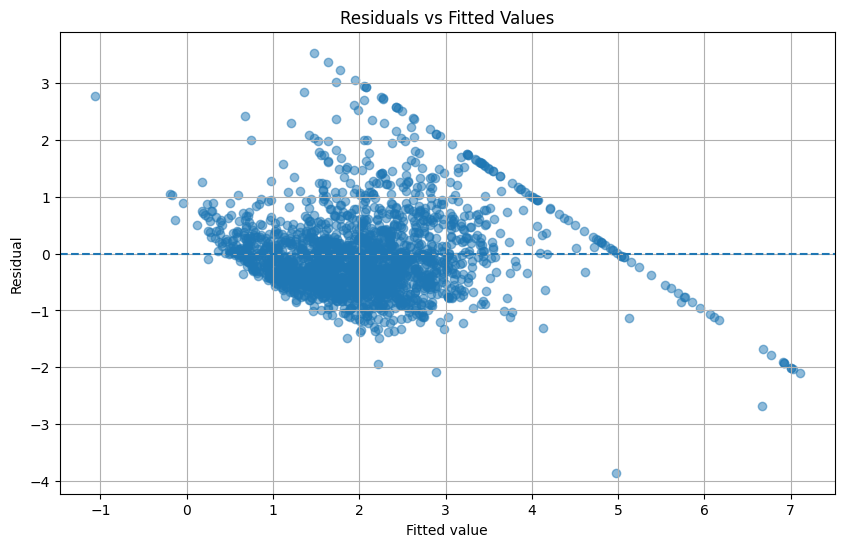

In [33]:
# TODO: calculate residuals and create the requested plot
# Calculate validation residuals
residuals = y_val - y_pred_closed

# Create residual plot
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_closed, residuals, alpha=0.5)

# Reference line at residual = 0
plt.axhline(0, linestyle='--')

plt.xlabel('Fitted value')
plt.ylabel('Residual')
plt.title('Residuals vs Fitted Values')
plt.show()

The residual plot shows an unusual pattern for observations with high fitted values, rather than being completely random around zero. This occurs because the California Housing target is capped at 5.0, corresponding to a maximum recorded house value of $500,000, causing many observations to have exactly the same target value.

## 6. Final test evaluation and reference implementation (5 points)

The test set should be used only after your implementations have been checked on the validation set. `scikit-learn` provides a tested implementation of OLS for a final comparison.

The coefficient of determination, $R^2$, measures how much better the model predicts than a baseline that always predicts the mean target value. It is defined as

$$R^2 = 1 - \frac{\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{N}(y_i-\bar{y})^2},$$

where $\bar{y}$ is the mean of the observed target values. An $R^2$ of $1$ indicates perfect predictions, $R^2=0$ means the model performs no better than the mean-prediction baseline, and a negative value means it performs worse than that baseline.

**TODO:** Use your closed-form model to make test predictions and report its test MSE and $R^2$. Compute $R^2$ directly from the definition above. Then fit `LinearRegression` on the scaled training data and report its test MSE and $R^2$. Compare the two implementations and briefly interpret the value of $R^2$.

In [34]:
y_test_pred_closed = predict(X_test_scaled, theta_closed)

closed_test_mse = mse(y_test, y_test_pred_closed)

y_mean = np.mean(y_test)
ss_res_closed = np.sum((y_test - y_test_pred_closed) ** 2)
ss_tot = np.sum((y_test - y_mean) ** 2)
closed_test_r2 = 1 - ss_res_closed / ss_tot


# Fitting scikit-learn's implementation of OLS on the scaled training data
sklearn_model = LinearRegression()
sklearn_model.fit(X_train_scaled, y_train)

y_test_pred_sklearn = sklearn_model.predict(X_test_scaled)

sklearn_test_mse = mse(y_test, y_test_pred_sklearn)

ss_res_sklearn = np.sum((y_test - y_test_pred_sklearn) ** 2)
sklearn_test_r2 = 1 - ss_res_sklearn / ss_tot


print(f'Closed-form OLS test MSE: {closed_test_mse:.3f}')
print(f'Closed-form OLS test R^2: {closed_test_r2:.3f}')
print(f'scikit-learn OLS test MSE: {sklearn_test_mse:.3f}')
print(f'scikit-learn OLS test R^2: {sklearn_test_r2:.3f}')

Closed-form OLS test MSE: 0.517
Closed-form OLS test R^2: 0.606
scikit-learn OLS test MSE: 0.517
scikit-learn OLS test R^2: 0.606


The linear model captures a substantial portion of the relationship between the features and house prices, as indicated by the test $R^2$ of 0.606. This means the model explains about 60.6% of the variation in house prices, while the remaining variation is not captured by this linear model.

# Part II — Multiclass Logistic Regression (25 points)

In this part, you will train and evaluate a multiclass logistic-regression classifier on the scikit-learn Digits dataset. You will use validation data to check the model during development, then evaluate it only once on a held-out test set.

Complete only the cells marked **TODO**. Do not change the data split or use the test set before the final evaluation.

## 0. Setup

Run this cell first. `load_digits` is bundled with scikit-learn, so no dataset download is required.

In [35]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, log_loss
)

## 1. Load and inspect the data

The Digits dataset consists of 8×8 grayscale images of handwritten digits. Each row of `X` is one flattened image with 64 pixel-intensity features, and the target is the digit from 0 to 9.

X shape: (1797, 64)
Classes: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']
Class counts: [178 182 177 183 181 182 181 179 174 180]


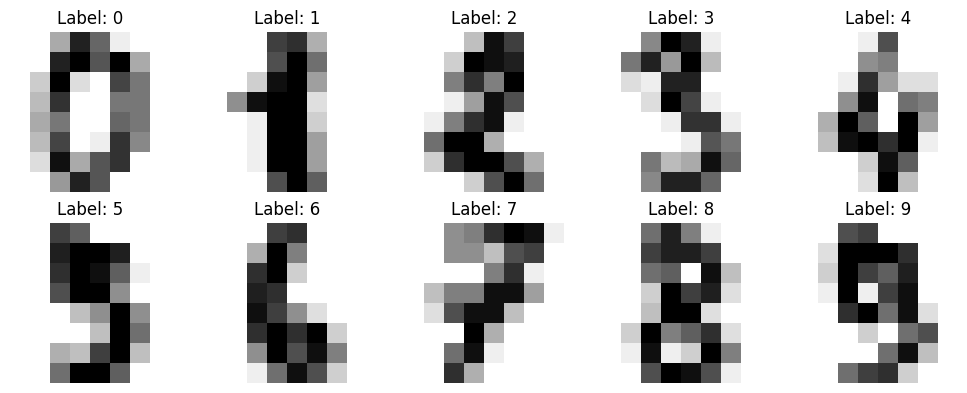

In [36]:
digits = load_digits()
X = digits.data
y = digits.target
class_names = np.array([str(label) for label in digits.target_names])

print(f'X shape: {X.shape}')
print(f'Classes: {class_names}')
print('Class counts:', np.bincount(y))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images[:10], y[:10]):
    ax.imshow(image, cmap='gray_r')
    ax.set_title(f'Label: {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Create train, validation, and test sets (3 points)

TODO: **Spilt 70% of the data for training, 15% for validation, and 15% for final testing**. The two calls below give the exact split while preserving class proportions.

In [37]:
# TODO 1: Change test_size parameter in below two lines
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print('Training set:  ', X_train.shape)
print('Validation set:', X_val.shape)
print('Test set:      ', X_test.shape)
print('Training class counts:', np.bincount(y_train))

Training set:   (1257, 64)
Validation set: (270, 64)
Test set:       (270, 64)
Training class counts: [124 127 124 128 127 127 127 125 122 126]


## 3. Standardize the features (2 point)

Fit the scaler on the **training data only**, then use that fitted scaler to transform validation and test data. This avoids information leakage and puts pixel features on comparable scales for optimization. Some pixels are always zero in the training data; `StandardScaler` handles these safely.

In [38]:
# TODO 2: Fit StandardScaler on X_train and transform all three splits.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## 4. Fit and evaluate multinomial logistic regression (10 points)

Fit `scikit-learn`'s multinomial logistic-regression model on training set. Then compute validation accuracy, macro-precision, macro-recall, macro-F1, and validation log loss using functions `accuracy_score`, and `precision_recall_fscore_support`. Experiment with different values of hyperparameter $C$ to select the best model.

In [39]:
model = LogisticRegression(C=0.1, solver='lbfgs', max_iter=2000, random_state=RANDOM_SEED)
#TODO 3: Fit sklearn's multinomial logistic-regression model.
model.fit(X_train_scaled, y_train)

# TODO 4: Make validation predictions and probabilities, then compute validation
# accuracy, macro-precision, macro-recall, macro-F1, and log loss.

y_val_pred = model.predict(X_val_scaled)
y_val_proba = model.predict_proba(X_val_scaled)

val_accuracy = accuracy_score(y_val, y_val_pred)

val_precision, val_recall, val_f1, _ = precision_recall_fscore_support(
    y_val,
    y_val_pred,
    average='macro'
)

val_log_loss = log_loss(y_val, y_val_proba)

# TODO 5: Print the metrics
print(f'Validation accuracy: {val_accuracy:.4f}')
print(f'Validation macro-precision: {val_precision:.4f}')
print(f'Validation macro-recall: {val_recall:.4f}')
print(f'Validation macro-F1: {val_f1:.4f}')
print(f'Validation log loss: {val_log_loss:.4f}')

#TODO 6: Experiment with different values of hyperparameter C to select the best model and update this code cell with that C value.
C_values = [0.01, 0.1, 1, 10, 100]

for C in C_values:
    temp_model = LogisticRegression(
        C=C,
        solver='lbfgs',
        max_iter=2000,
        random_state=RANDOM_SEED
    )

    temp_model.fit(X_train_scaled, y_train)

    pred = temp_model.predict(X_val_scaled)
    proba = temp_model.predict_proba(X_val_scaled)

    accuracy = accuracy_score(y_val, pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, pred, average='macro'
    )

    loss = log_loss(y_val, proba)

    print(
        f"C={C:<5} "
        f"Accuracy={accuracy:.4f} "
        f"Precision={precision:.4f} "
        f"Recall={recall:.4f} "
        f"F1={f1:.4f} "
        f"LogLoss={loss:.4f}"
    )

Validation accuracy: 0.9630
Validation macro-precision: 0.9639
Validation macro-recall: 0.9632
Validation macro-F1: 0.9629
Validation log loss: 0.1608
C=0.01  Accuracy=0.9444 Precision=0.9451 Recall=0.9444 F1=0.9439 LogLoss=0.4042
C=0.1   Accuracy=0.9630 Precision=0.9639 Recall=0.9632 F1=0.9629 LogLoss=0.1608
C=1     Accuracy=0.9593 Precision=0.9596 Recall=0.9595 F1=0.9592 LogLoss=0.1029
C=10    Accuracy=0.9593 Precision=0.9600 Recall=0.9592 F1=0.9591 LogLoss=0.1210
C=100   Accuracy=0.9444 Precision=0.9455 Recall=0.9447 F1=0.9444 LogLoss=0.1753


**TODO 7.** Briefly explain why macro-F1 is a reasonable metric to report alongside accuracy for a multiclass problem.

Macro-F1 is useful alongside accuracy because it calculates the F1-score separately for each class and gives all classes equal importance. While accuracy measures overall correct predictions, macro-F1 shows whether the model performs well across all digit classes and can reveal poor performance on individual classes.

## 5. Final held-out test evaluation (10 points)

Now, evaluate the fitted model on the test set. Report test accuracy and macro-F1, display the confusion matrix.

Test accuracy: 0.9741
Test macro-F1: 0.9741


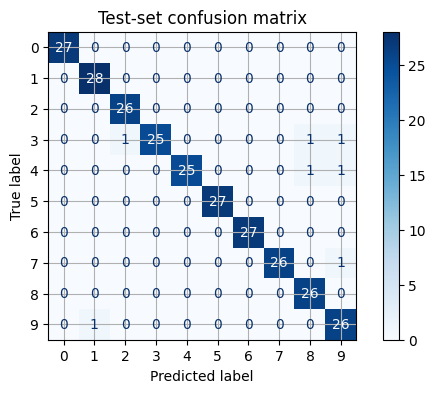

In [40]:
# TODO 8: Evaluate model on the test set

# Make predictions
y_test_pred = model.predict(X_test_scaled)

# Test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

# Test macro-F1
_, _, test_f1, _ = precision_recall_fscore_support(
    y_test,
    y_test_pred,
    average='macro'
)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Print results
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test macro-F1: {test_f1:.4f}')

# Display the test confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap='Blues')

plt.title('Test-set confusion matrix')
plt.show()

**TODO 9.** From the confusion matrix, identify pairs of digits the model confuses.

The model mainly confuses 3 with 8/9 and 4 with 8/9, with a few additional errors such as 7 being classified as 9 and 9 being classified as 1. These errors are likely due to similarities in the handwritten shapes of these digits.

## Before submitting

- Run all cells from top to bottom after completing the TODOs.
- Ensure that your written answers are concise and complete.
